# 04 - India Case Study
Why India? It is one of the world's largest food producers, its farming depends on the **monsoon**, and farmers are vulnerable to climate variability. We repeat the pipeline on a state-level Indian dataset (1997-2020) and compare with the global picture.

In [1]:
import sys; sys.path.append("..")
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from IPython.display import Markdown, display, Image
from src import config as C, india, data, evaluate
%matplotlib inline
sns.set_theme(style="whitegrid"); pd.set_option("display.width", 200)
def save(name):
    plt.tight_layout(); plt.savefig(C.FIG_DIR / name, dpi=130); plt.show()

## 1. Cleaning
Steps: strip whitespace in text columns (Season/State had trailing spaces), drop rows with missing/zero Area or Production, **recompute yield = Production / Area**, compare with the shipped `Yield`, **exclude Coconut** (recorded in number of nuts, not tonnes - a different unit would dominate squared-error metrics), then remove extreme yield outliers *per crop*.

In [2]:
df = india.clean(); info = india.clean.info; print(df.shape)

{
 "rows_raw": 19689,
 "after_zero_missing_drop": 19577,
 "excluded_other_unit_rows": 165,
 "median_abs_diff": 0.055599590093314166,
 "max_abs_diff": 343.1915736040609,
 "pct_rows_rel_diff_gt_1pct": 79.31176591798888,
 "outliers_removed": 216,
 "rows_final": 19196
}
(19196, 10)


In [3]:
display(Markdown(f'''**Documented differences.** The shipped `Yield` column differs from Production/Area: median absolute difference {info["median_abs_diff"]:.3f}, maximum {info["max_abs_diff"]:.0f}, and {info["pct_rows_rel_diff_gt_1pct"]:.0f}% of rows differ by more than 1%. The source does not explain the discrepancy (probably Area/Production were revised after Yield was computed), so we use the **recomputed value as the target** because it is internally consistent with the Area and Production we can see.

**Outlier rule.** For each crop with ≥ 20 rows we drop yields outside Q1 − 3·IQR and Q3 + 3·IQR (wide fence: only extreme values, e.g. typos, are removed). This removed **{info["outliers_removed"]}** rows. Per-crop is needed because crops have totally different yield scales (sugarcane yields ~50 t/ha, pulses ~0.5).'''))
print(df.Season.unique(), df.State.nunique(), df.Crop.nunique())

**Documented differences.** The shipped `Yield` column differs from Production/Area: median absolute difference 0.056, maximum 343, and 79% of rows differ by more than 1%. The source does not explain the discrepancy (probably Area/Production were revised after Yield was computed), so we use the **recomputed value as the target** because it is internally consistent with the Area and Production we can see.

**Outlier rule.** For each crop with ≥ 20 rows we drop yields outside Q1 − 3·IQR and Q3 + 3·IQR (wide fence: only extreme values, e.g. typos, are removed). This removed **216** rows. Per-crop is needed because crops have totally different yield scales (sugarcane yields ~50 t/ha, pulses ~0.5).

<ArrowStringArray>
['Whole Year', 'Kharif', 'Rabi', 'Autumn', 'Summer', 'Winter']
Length: 6, dtype: str 30 54


## 2. Exploratory analysis

### 2.1 Top states by production
Coconut is excluded from the cleaned data (it is counted in nuts, not tonnes).

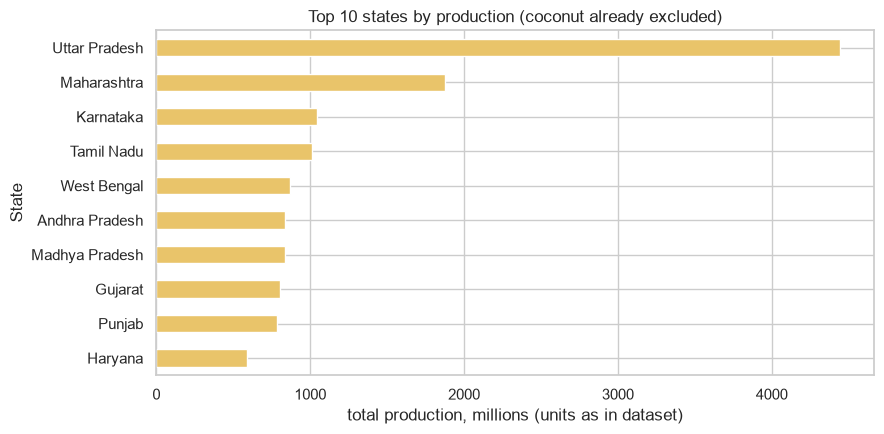

In [4]:
tp = df.groupby("State")[C.I_PROD].sum().sort_values(ascending=False).head(10)
plt.figure(figsize=(9, 4.5)); (tp[::-1] / 1e6).plot.barh(color="#e9c46a"); plt.xlabel("total production, millions (units as in dataset)")
plt.title("Top 10 states by production (coconut already excluded)"); save("india_top_states.png")

### 2.2 Yield by season

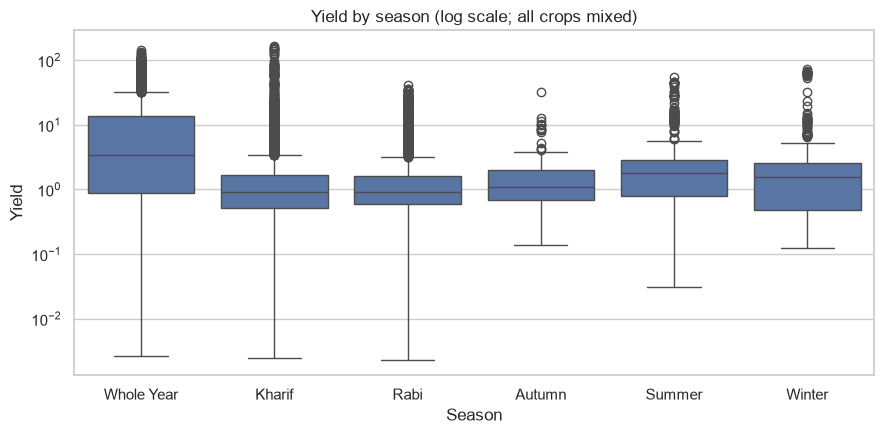

,count,median,mean
Season,,,
Autumn,412,1.10,1.58
Kharif,8113,0.92,2.42
Rabi,5683,0.92,1.96
Summer,1182,1.78,3.03
Whole Year,3417,3.46,13.62
Winter,389,1.54,5.39


In [5]:
plt.figure(figsize=(9, 4.5)); sns.boxplot(data=df, x=C.I_SEASON, y=C.I_TARGET); plt.yscale("log")
plt.title("Yield by season (log scale; all crops mixed)"); save("india_yield_by_season.png")
display(df.groupby(C.I_SEASON)[C.I_TARGET].agg(["count", "median", "mean"]).round(2))

Crops differ so much that season medians mix crop effects (e.g. sugarcane is 'Whole Year' and has very high yield). So we also test season within one crop (section 2.7).

### 2.3 Yield trends for major crops

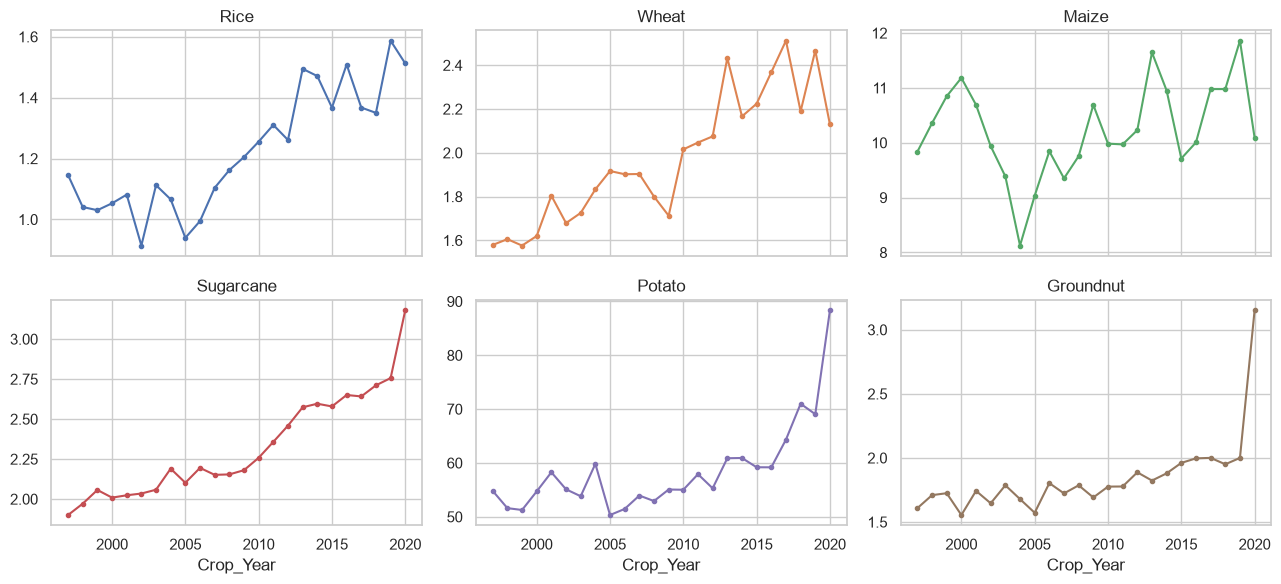

{'Rice': np.float64(0.043), 'Wheat': np.float64(0.029), 'Maize': np.float64(0.037), 'Sugarcane': np.float64(0.828), 'Potato': np.float64(0.036), 'Groundnut': np.float64(0.024)}


In [6]:
major = ["Rice", "Wheat", "Maize", "Sugarcane", "Potato", "Groundnut"]
tr = df[df.Crop.isin(major)].groupby([C.I_YEAR, C.I_CROP])[C.I_TARGET].median().unstack()
tr.plot(subplots=True, layout=(2, 3), figsize=(13, 6), marker="o", ms=3, sharex=True, legend=False, title=major)
save("india_yield_trends.png")
slopes = {c: stats.linregress(tr[c].dropna().index, tr[c].dropna()).slope for c in major}; print({k: round(v, 3) for k, v in slopes.items()})

### 2.4 State × crop yield heatmap

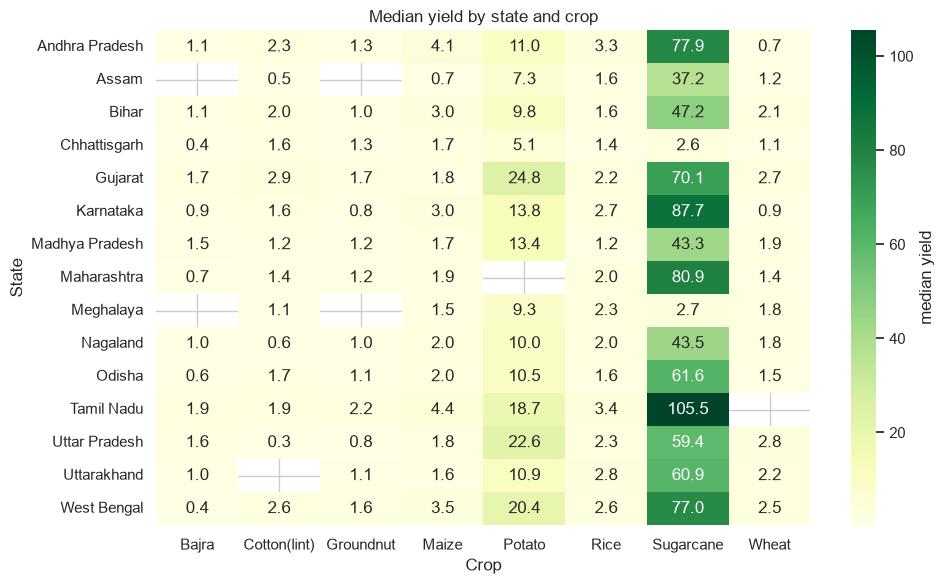

In [7]:
crops = ["Rice", "Wheat", "Maize", "Sugarcane", "Potato", "Groundnut", "Bajra", "Cotton(lint)"]
states = df.State.value_counts().head(15).index
hm = df[df.Crop.isin(crops) & df.State.isin(states)].pivot_table(index=C.I_STATE, columns=C.I_CROP, values=C.I_TARGET, aggfunc="median")
plt.figure(figsize=(10, 6)); sns.heatmap(hm, annot=True, fmt=".1f", cmap="YlGn", cbar_kws={"label": "median yield"})
plt.title("Median yield by state and crop"); save("india_state_crop_heatmap.png")

### 2.5 Rainfall, fertilizer and pesticide vs yield
Fertilizer and pesticide are *totals* in the dataset, so we plot them **per hectare** (total ÷ area) to remove the effect of farm size. Rice only, so crop effects do not hide the pattern.

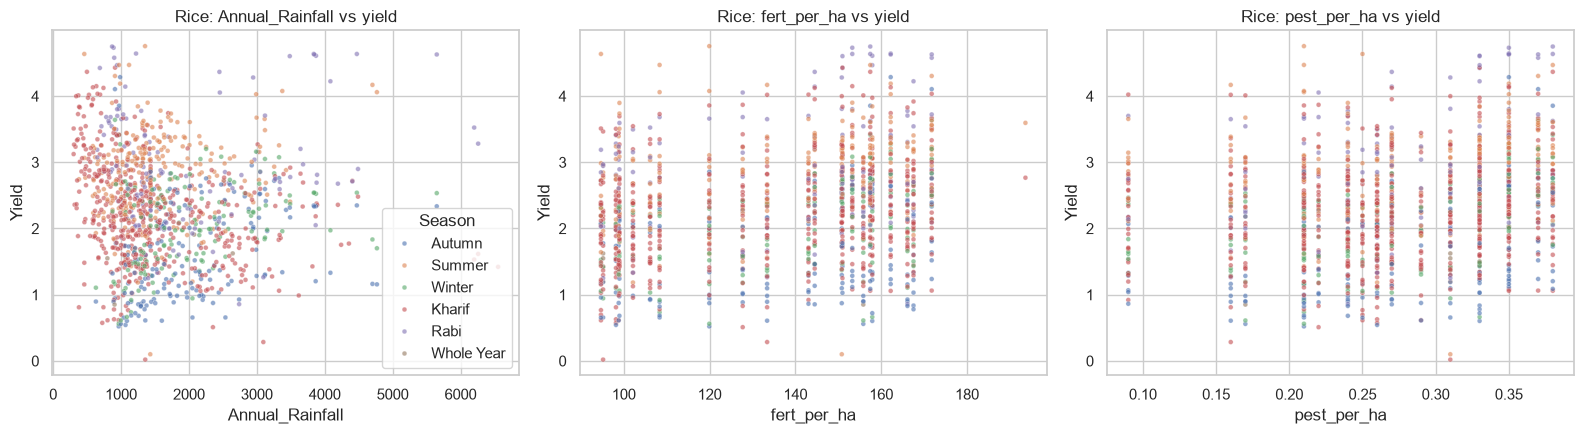

Annual_Rainfall: Spearman rho=-0.134 p=3.4e-06
fert_per_ha: Spearman rho=0.250 p=1.6e-18
pest_per_ha: Spearman rho=0.240 p=4e-17


In [8]:
rice = df[df.Crop == "Rice"].copy()
rice["fert_per_ha"] = rice[C.I_FERT] / rice[C.I_AREA]; rice["pest_per_ha"] = rice[C.I_PEST] / rice[C.I_AREA]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, c in zip(ax, [C.I_RAIN, "fert_per_ha", "pest_per_ha"]):
    sns.scatterplot(data=rice, x=c, y=C.I_TARGET, hue=C.I_SEASON, s=12, alpha=.6, ax=a, legend=a is ax[0]); a.set_title(f"Rice: {c} vs yield")
save("india_drivers_scatter.png")
res = {c: stats.spearmanr(rice[c], rice[C.I_TARGET]) for c in [C.I_RAIN, "fert_per_ha", "pest_per_ha"]}
for c, r in res.items(): print(f"{c}: Spearman rho={r[0]:.3f} p={r[1]:.2g}")

### 2.6 Compare with simple correlations (all rows)

In [9]:
d2 = df.assign(fert_ha=df[C.I_FERT] / df[C.I_AREA], pest_ha=df[C.I_PEST] / df[C.I_AREA])
display(d2[[C.I_RAIN, "fert_ha", "pest_ha", C.I_YEAR, C.I_TARGET]].corr(method="spearman").round(2))

,Annual_Rainfall,fert_ha,pest_ha,Crop_Year,Yield
Annual_Rainfall,1.00,0.02,0.03,0.02,0.04
fert_ha,0.02,1.00,0.52,0.87,0.08
pest_ha,0.03,0.52,1.00,0.66,0.07
Crop_Year,0.02,0.87,0.66,1.00,0.09
Yield,0.04,0.08,0.07,0.09,1.00


### 2.7 Statistical tests
**Kruskal-Wallis:** does Rice yield differ across seasons? (non-parametric because yields are skewed). **Spearman:** is rainfall related to Rice yield?

In [10]:
seas = [g[C.I_TARGET].values for s, g in rice.groupby(C.I_SEASON) if len(g) >= 10]
H, pk = stats.kruskal(*seas)
rho, pr = res[C.I_RAIN]
print(f"Kruskal-Wallis across seasons (rice): H={H:.1f}, p={pk:.2g}; Spearman rainfall~yield: rho={rho:.3f}, p={pr:.2g}")
display(rice.groupby(C.I_SEASON)[C.I_TARGET].agg(["count", "median"]).round(2))

Kruskal-Wallis across seasons (rice): H=289.9, p=1.6e-61; Spearman rainfall~yield: rho=-0.134, p=3.4e-06


,count,median
Season,,
Autumn,158,1.41
Kharif,505,2.19
Rabi,139,2.78
Summer,244,2.87
Whole Year,4,1.59
Winter,147,2.04


In [11]:
display(Markdown(f"**Interpretation.** Kruskal-Wallis p = {pk:.2g} {'< 0.05: rice yield differs significantly between seasons (e.g. Rabi/Summer irrigated rice vs rain-fed Kharif/Autumn rice).' if pk < .05 else '>= 0.05: no significant seasonal difference.'} "
f"Rainfall vs rice yield: rho = {rho:.2f} (p = {pr:.2g}), a {'weak' if abs(rho) < .3 else 'moderate'} association: a plausible reason is that much Indian rice is irrigated, and rainfall is a state-level annual total so it cannot capture timing of the monsoon. Association, not causation."))

**Interpretation.** Kruskal-Wallis p = 1.6e-61 < 0.05: rice yield differs significantly between seasons (e.g. Rabi/Summer irrigated rice vs rain-fed Kharif/Autumn rice). Rainfall vs rice yield: rho = -0.13 (p = 3.4e-06), a weak association: a plausible reason is that much Indian rice is irrigated, and rainfall is a state-level annual total so it cannot capture timing of the monsoon. Association, not causation.

## 3. Modelling
We use the **best two model types from the global study** (Random Forest and XGBoost) and both splits. Features: Crop, Crop_Year, Season, State, Area, Annual_Rainfall, Fertilizer, Pesticide. **Production is NOT a feature**: yield = Production/Area, so including it would hand the model the answer (target leakage). The time split trains on 1997-2016 and tests on 2017-2020.


== random split


,model,cv_R2_mean,cv_R2_std,test_R2,test_MAE,test_RMSE,train_time_s
0,RandomForest,0.954,0.009,0.967,0.620,2.126,2.707
1,XGBoost,0.955,0.010,0.971,0.701,1.984,0.567
2,XGBoost (tuned),0.958,0.006,0.971,0.641,1.987,1.570
3,RandomForest (tuned),0.953,0.009,0.965,0.787,2.168,1.289



== time split


,model,cv_R2_mean,cv_R2_std,test_R2,test_MAE,test_RMSE,train_time_s
0,RandomForest,0.925,0.005,0.917,0.898,3.652,2.888
1,XGBoost,0.931,0.003,0.902,0.989,3.981,0.569
2,XGBoost (tuned),0.935,0.010,0.927,1.081,3.439,0.260
3,RandomForest (tuned),0.924,0.006,0.917,1.048,3.655,1.340


Best India model (time-split CV R2): XGBoost (tuned)


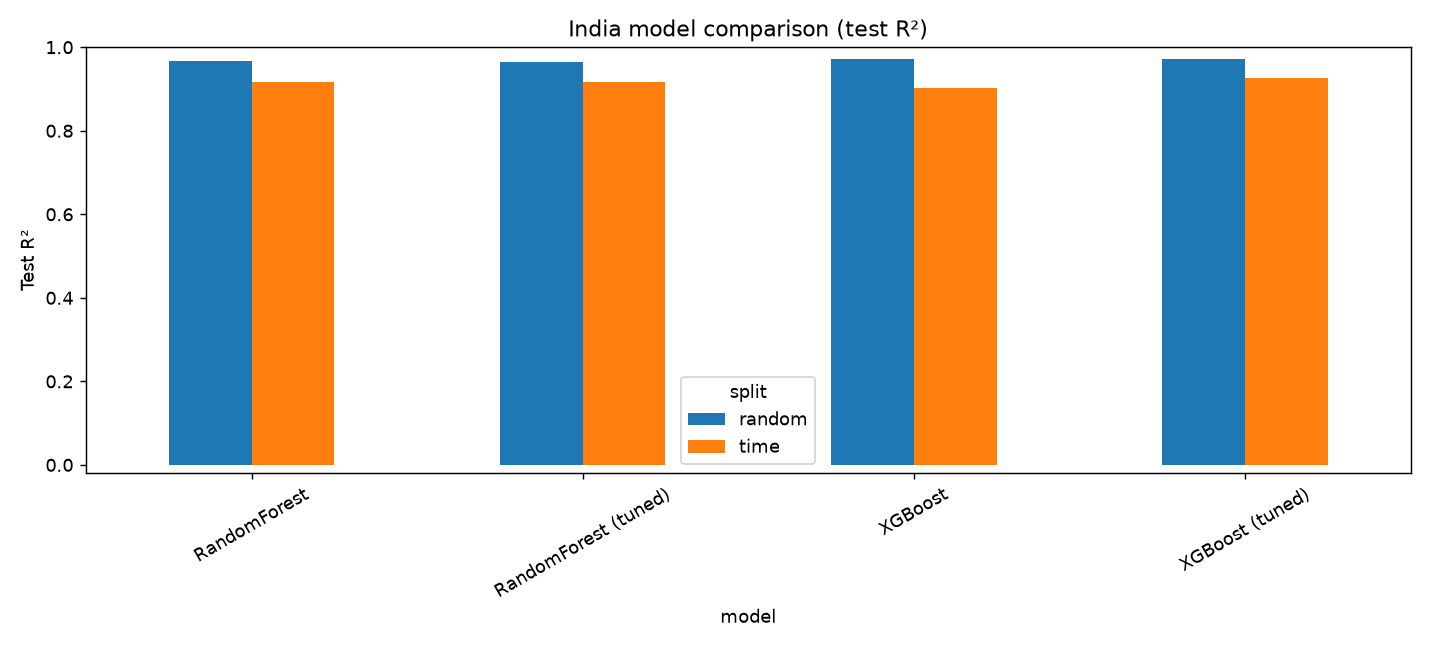

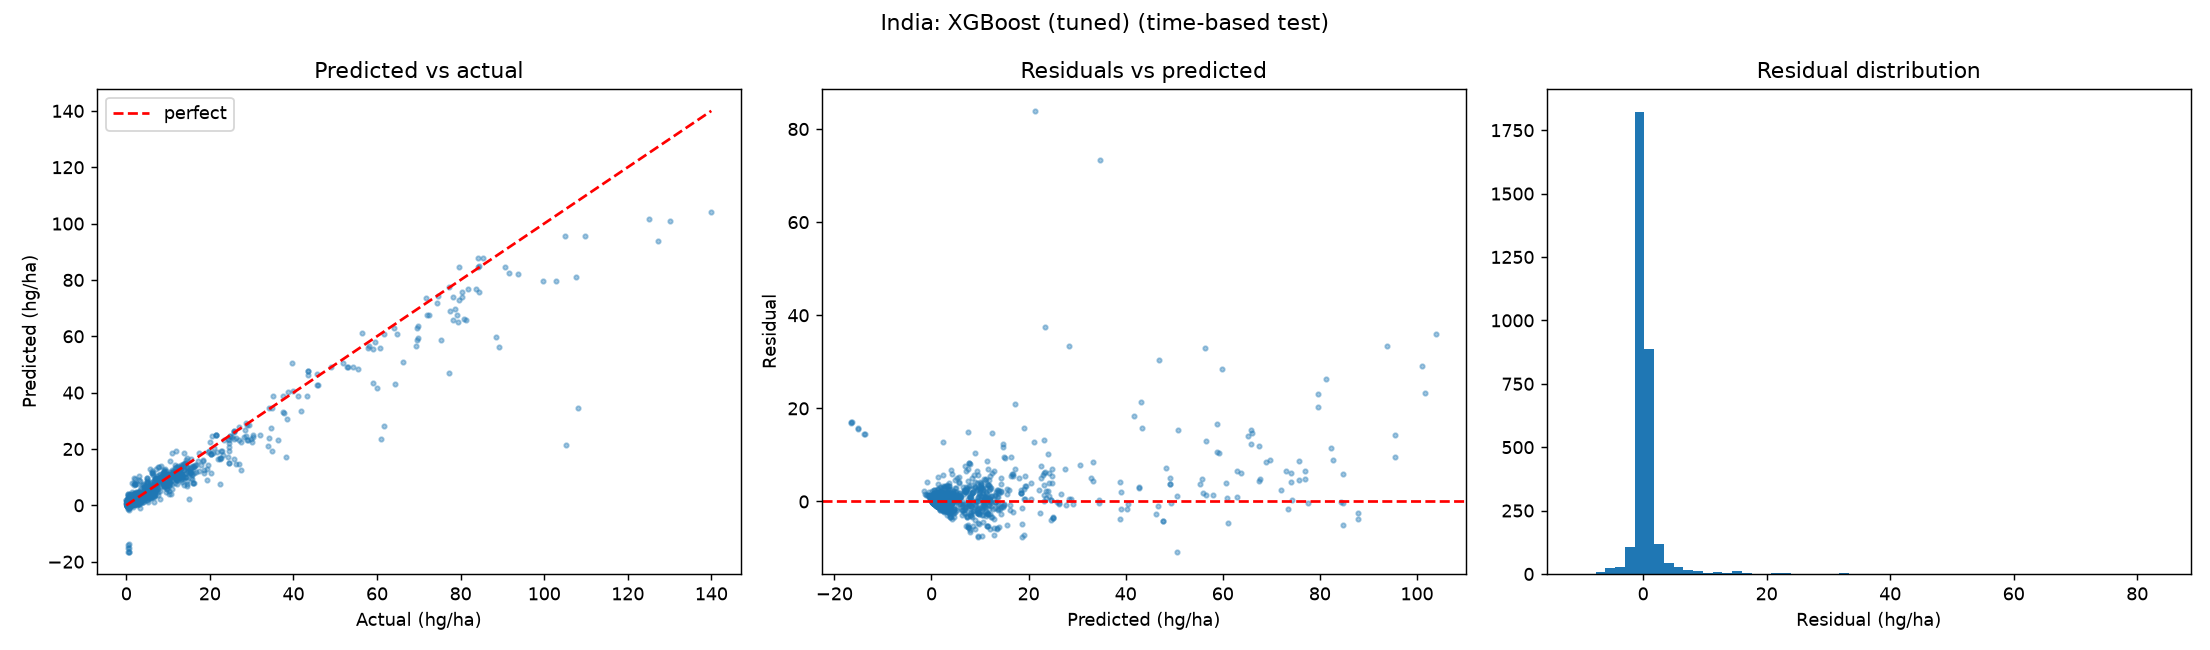

In [12]:
comp = pd.read_csv(C.INDIA_COMPARISON_CSV); meta_i = __import__("joblib").load(C.INDIA_META_PATH)
cols = ["model", "cv_R2_mean", "cv_R2_std", "test_R2", "test_MAE", "test_RMSE", "train_time_s"]
for s in ["random", "time"]:
    print("\n==", s, "split"); display(comp[comp.split == s][cols].round(3).reset_index(drop=True))
print("Best India model (time-split CV R2):", meta_i["best_name"])
display(Image(str(C.FIG_DIR / "india_model_comparison.png"))); display(Image(str(C.FIG_DIR / "india_pred_vs_actual.png")))

### Random vs time-based split in India

In [13]:
bn = meta_i["best_name"]; base = bn.replace(" (tuned)", "")
g = comp.set_index(["split", "model"])
r_, t_ = g.loc[("random", base)], g.loc[("time", base)]
display(Markdown(f"**Same pattern as the global study.** {base} (untuned): random-split test R² **{r_.test_R2:.3f}** vs time-split **{t_.test_R2:.3f}**; RMSE {r_.test_RMSE:.2f} -> {t_.test_RMSE:.2f} t/ha and MAE {r_.test_MAE:.2f} -> {t_.test_MAE:.2f}. Random splitting lets the model see the same state-crop-season series in neighbouring years (leakage), while the time split forces it to forecast 2017-2020 from 1997-2016 data. Crop/state series also drift over time (policy, irrigation, new varieties), which a random split hides. **We therefore select the India model on the time-split**."))
print("test rows per year (time split):", data.time_split(df, C.I_YEAR, C.I_TEST_YEARS)[1][C.I_YEAR].value_counts().sort_index().to_dict())
ex, test_i, _ = india.load_india_explainer()

**Same pattern as the global study.** XGBoost (untuned): random-split test R² **0.971** vs time-split **0.902**; RMSE 1.98 -> 3.98 t/ha and MAE 0.70 -> 0.99. Random splitting lets the model see the same state-crop-season series in neighbouring years (leakage), while the time split forces it to forecast 2017-2020 from 1997-2016 data. Crop/state series also drift over time (policy, irrigation, new varieties), which a random split hides. **We therefore select the India model on the time-split**.

test rows per year (time split): {2017: 1034, 2018: 1031, 2019: 1034, 2020: 37}


Note: the year 2020 has only 37 rows in the source data, so the test period is effectively 2017-2019.

## 4. SHAP explanations for India

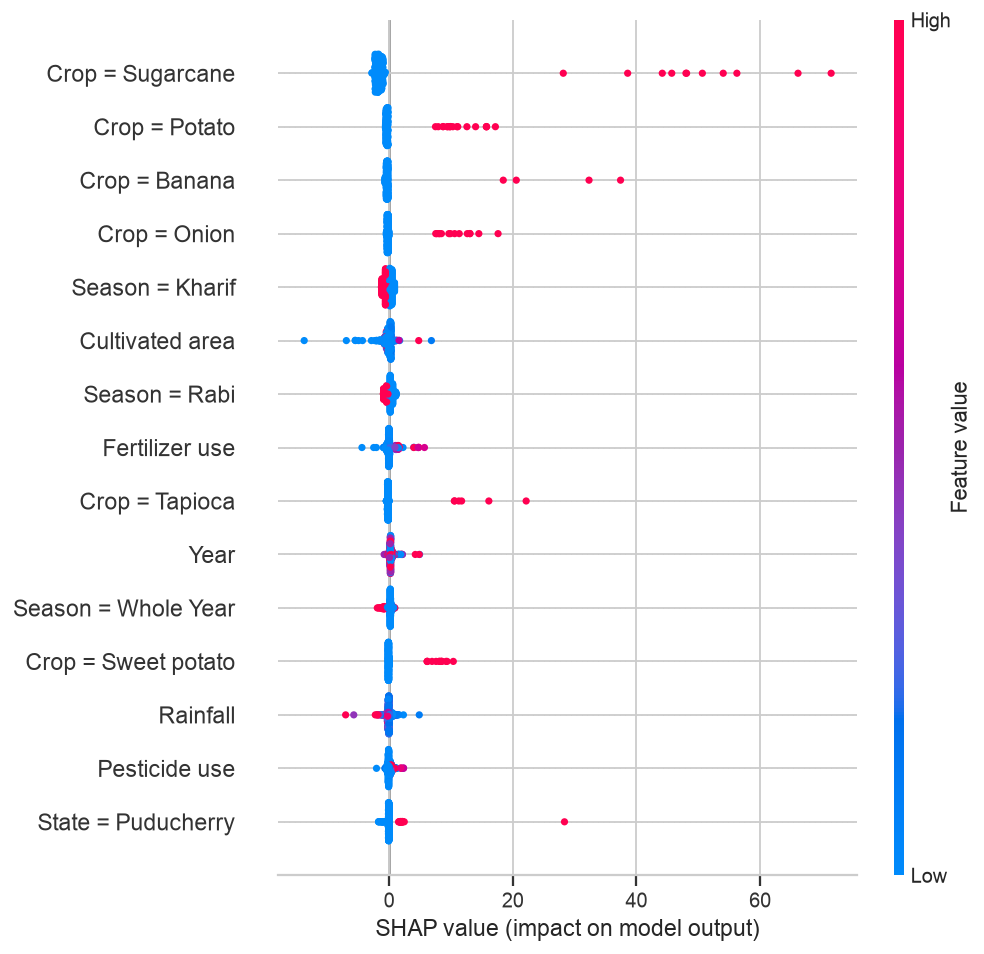

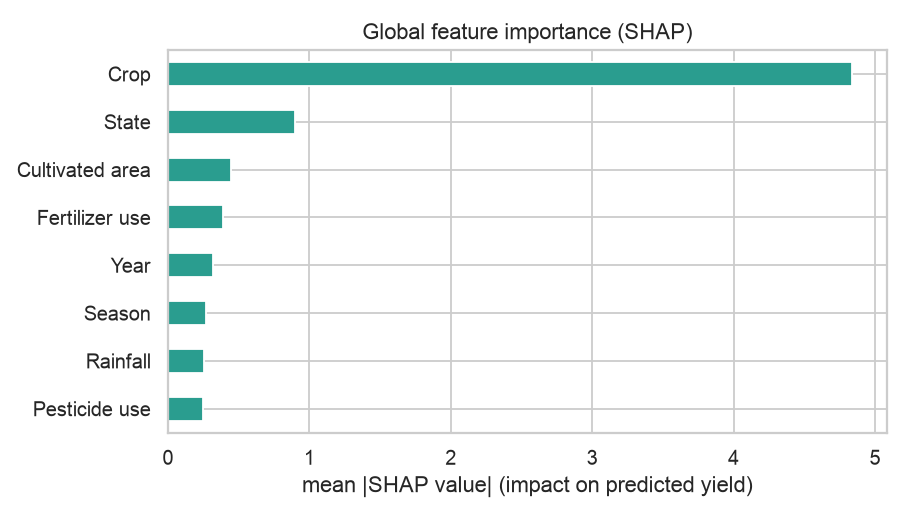

In [14]:
sample = test_i[C.I_FEATURES].sample(min(500, len(test_i)), random_state=C.RANDOM_STATE)
ex.beeswarm(sample, C.FIG_DIR / "india_shap_beeswarm.png"); display(Image(str(C.FIG_DIR / "india_shap_beeswarm.png")))
ex.bar_plot(sample, C.FIG_DIR / "india_shap_bar.png"); display(Image(str(C.FIG_DIR / "india_shap_bar.png")))

{'Crop': 'Rice', 'Season': 'Kharif', 'State': 'Punjab', 'Crop_Year': 2019, 'Area': 3142000.0, 'Annual_Rainfall': 653.2, 'Fertilizer': 539669920.0, 'Pesticide': 1162540.0}


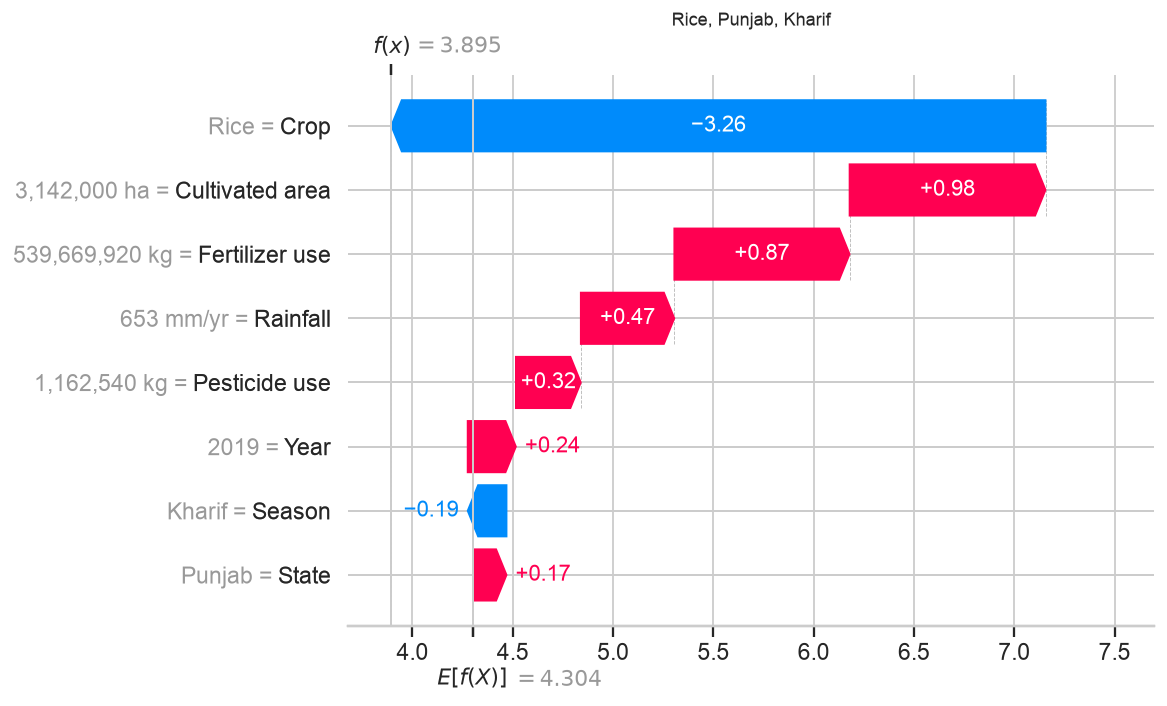

The model predicts 3.89 t/ha (average prediction: 4.30). Crop 'Rice' reduced the predicted yield by 3.26 t/ha; Cultivated area (3,142,000 ha) increased the predicted yield by 0.98 t/ha; High fertilizer use (539,669,920 kg) increased the predicted yield by 0.87 t/ha.
actual yield: 4.03 t/ha


In [15]:
row = india.example_row(df, "Rice", "Punjab", "Kharif"); print(row.to_dict("records")[0])
ex.waterfall(row, C.FIG_DIR / "india_shap_waterfall_rice_punjab.png", title="Rice, Punjab, Kharif")
display(Image(str(C.FIG_DIR / "india_shap_waterfall_rice_punjab.png")))
sent = ex.sentence(row, unit="t/ha"); print(sent)
actual = df.loc[row.index, C.I_TARGET].iloc[0]; print("actual yield:", round(actual, 2), "t/ha")

Reading: the sentence above explains the biggest three drivers for this Punjab rice example in plain English. Punjab is highly irrigated and fertilised, which is why 'State' and 'Crop' contribute positively.

## 5. India vs the world (same crops)
Using `yield_df.csv` rows where `Area == 'India'` against the world average for the same crop (all countries, same year), in t/ha.

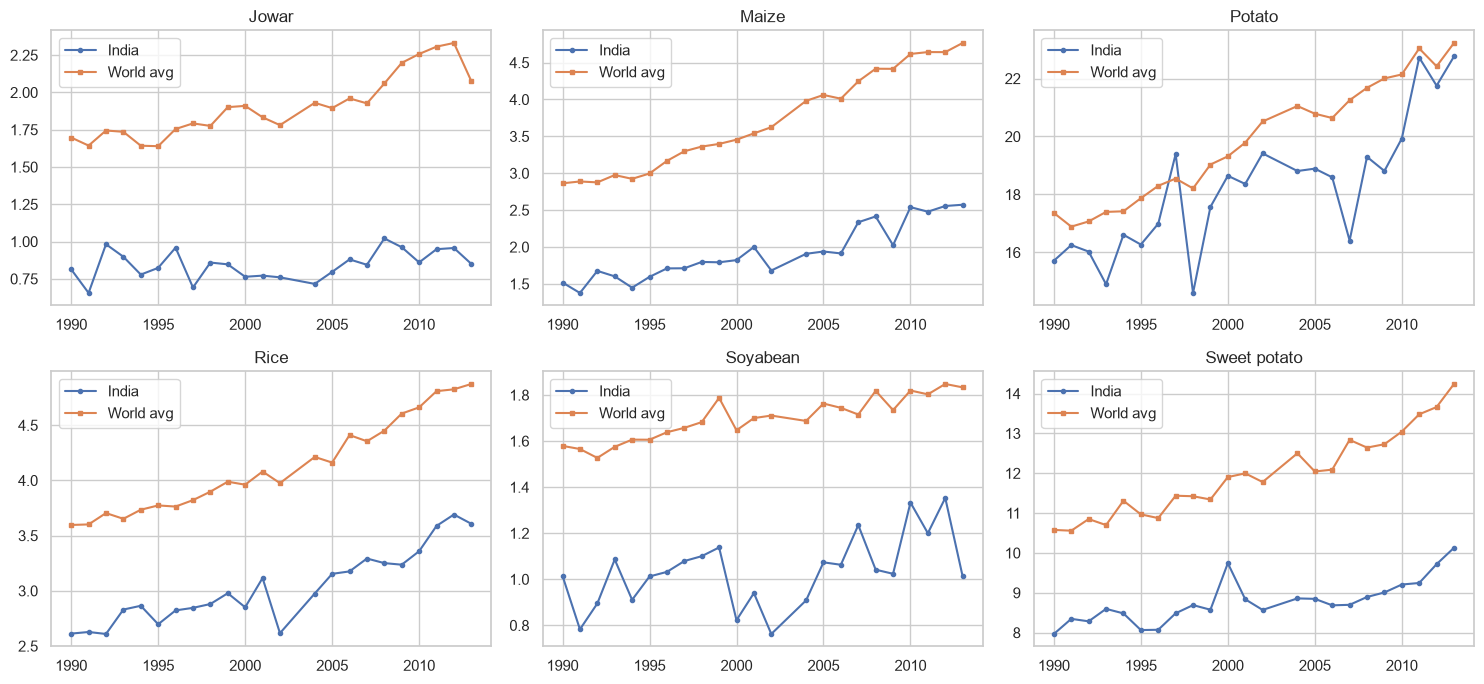

,india_t_ha,world_avg_t_ha,ratio
crop,,,
Jowar,0.85,1.90,0.44
Maize,1.93,3.70,0.52
Potato,18.21,19.82,0.92
Rice,3.03,4.13,0.73
Soyabean,1.04,1.70,0.61
Sweet potato,8.78,11.96,0.73
Wheat,2.65,3.01,0.88


In [16]:
cmp = india.global_comparison()
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for a, (c, g) in zip(axes.ravel(), cmp.groupby("crop")):
    a.plot(g.year, g.india_t_ha, label="India", marker="o", ms=3); a.plot(g.year, g.world_avg_t_ha, label="World avg", marker="s", ms=3); a.set_title(c); a.legend()
for a in axes.ravel()[cmp.crop.nunique():]: a.axis("off")
save("india_vs_world.png")
s = cmp.groupby("crop")[["india_t_ha", "world_avg_t_ha"]].mean(); s["ratio"] = s.india_t_ha / s.world_avg_t_ha; display(s.round(2))

In [17]:
display(Markdown("**Insights.** " + "; ".join(f"{c}: India averages {r.india_t_ha:.1f} t/ha vs world {r.world_avg_t_ha:.1f} ({r.ratio*100:.0f}%)" for c, r in s.iterrows()) + ". Yields that sit below the world average point to room for improvement through irrigation, better varieties and balanced fertilisation, whereas India is above the average for some crops."))

**Insights.** Jowar: India averages 0.8 t/ha vs world 1.9 (44%); Maize: India averages 1.9 t/ha vs world 3.7 (52%); Potato: India averages 18.2 t/ha vs world 19.8 (92%); Rice: India averages 3.0 t/ha vs world 4.1 (73%); Soyabean: India averages 1.0 t/ha vs world 1.7 (61%); Sweet potato: India averages 8.8 t/ha vs world 12.0 (73%); Wheat: India averages 2.7 t/ha vs world 3.0 (88%). Yields that sit below the world average point to room for improvement through irrigation, better varieties and balanced fertilisation, whereas India is above the average for some crops.

## 6. Key India insights

In [18]:
ins = [
 f"**Cleaning matters:** {info['rows_raw'] - info['rows_final']:,} of {info['rows_raw']:,} rows were removed ({info['rows_raw']-info['after_zero_missing_drop']} zero/missing Production/Area, {info['excluded_other_unit_rows']} coconut rows (different unit), {info['outliers_removed']} extreme yields).",
 f"**Crop and state explain most yield variation** - top SHAP features: " + ", ".join(f"{C.I_LABELS[k]}" for k in ex.mean_abs_grouped(sample).index[:3]) + ".",
 f"**Rice yield differs by season** (Kruskal-Wallis p = {pk:.2g}).",
 f"**Rainfall is only weakly associated with rice yield** (Spearman rho = {rho:.2f}) (plausibly because irrigation buffers the monsoon; we cannot test that with this data).",
 f"**Best India model:** {meta_i['best_name']} - time-split test R² {comp[(comp.split=='time')&(comp.model==meta_i['best_name'])].test_R2.iloc[0]:.3f}.",
]
display(Markdown("\n".join(f"{i+1}. {t}" for i, t in enumerate(ins))))

1. **Cleaning matters:** 493 of 19,689 rows were removed (112 zero/missing Production/Area, 165 coconut rows (different unit), 216 extreme yields).
2. **Crop and state explain most yield variation** - top SHAP features: Crop, State, Cultivated area.
3. **Rice yield differs by season** (Kruskal-Wallis p = 1.6e-61).
4. **Rainfall is only weakly associated with rice yield** (Spearman rho = -0.13) (plausibly because irrigation buffers the monsoon; we cannot test that with this data).
5. **Best India model:** XGBoost (tuned) - time-split test R² 0.927.